# Taller de Aprendizaje No Supervisado
## Parte 2: Segmentación de Clientes de Tarjeta de Crédito (variables numéricas)

### Credit Card Dataset

[Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)

Resume el comportamiento de uso de unos **9.000 titulares** de tarjeta durante los últimos 6 meses, con **17 variables numéricas de comportamiento** (saldo, compras, adelantos de efectivo, límite de crédito, pagos...).

> **Diferencia clave con el dataset de setas:** aquí **no hay etiqueta**. El objetivo *es* encontrar segmentos de clientes para definir una estrategia de marketing. Esto es aprendizaje no supervisado «de verdad»: no podemos calcular ARI porque no hay verdad de referencia; nos guiamos por métricas internas y por la **interpretabilidad** de los segmentos.

Además, al ser numérico y con escalas muy distintas, aparecen dos pasos que con las setas no hicieron falta: **imputar nulos** y **escalar**.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
# Importad el resto a medida que los necesiteis (TSNE, GMM, DBSCAN, metricas...)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

### Leer conjunto de datos y primer vistazo

In [2]:
# Leer el csv (esta en 'data/credit_card.csv') y mostrar las primeras filas.
df = pd.read_csv("data/credit_card.csv")   # cargamos el dataset de tarjetas
df.head()                                  # vistazo a las 5 primeras filas

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


### Exploración de datos

In [6]:
# Tamaño: (número de clientes, número de variables).
print("Filas y columnas:", df.shape)

Filas y columnas: (8950, 18)


In [4]:
# Descripcion estadistica. Fijaos en las escalas tan distintas entre variables.
df.describe().T   # .T = traspuesta: una fila por variable, más fácil de leer con 17 columnas

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


> **📝 Observación:**
> - **Escalas muy distintas:** `BALANCE` llega a 19.043 y `PURCHASES_FREQUENCY` a 1 (≈ 19.000 veces más).
>   Como K-Means y PCA usan distancias, las variables grandes dominarían → habrá que **escalar**.
> - **Variables sesgadas:** en `PURCHASES` la media (1.003) es casi el triple de la mediana (361) y el máximo es 49.040:
>   pocos clientes gastan muchísimo. Por eso usaremos la **mediana** para imputar.
> - **Dato raro:** `CASH_ADVANCE_FREQUENCY` es una frecuencia (0–1), pero su máximo es **1,5** → posible error en los datos.


In [5]:
# Tipos de datos.
df.info()   # tipo de dato y nº de valores no nulos por columna

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

> **📝 Observación:** 8950 clientes y 18 columnas. Todas son **numéricas** salvo `CUST_ID`, un identificador
> que no describe el comportamiento del cliente (por eso `describe()` muestra 17) → lo eliminaremos.

#### Nulos

In [7]:
# Contar nulos por variable (mostrad solo las que tengan).
nulos = df.isnull().sum()   # nº de nulos por columna
nulos[nulos > 0]            # solo las columnas con algún nulo

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Hay nulos en `CREDIT_LIMIT` (1) y `MINIMUM_PAYMENTS` (~313). Al ser variables numéricas muy sesgadas, los imputamos con la **mediana** (más robusta que la media).

**¿Por qué la mediana y no la media?** Porque las variables están muy **sesgadas**: unos pocos clientes con valores
enormes tiran de la media hacia arriba, mientras que la mediana representa al cliente **típico**.

**Analogía:** en un colegio, 9 profesores cobran 2.000 € y el director 20.000 €.
La media es **3.800 €** (no se parece al sueldo de nadie); la mediana es **2.000 €** (el sueldo típico).
Si tuviéramos que rellenar un sueldo desconocido, la mediana sería mucho más razonable.

**Pasos:**
1. Eliminamos `CUST_ID`: es solo un identificador, no describe el comportamiento del cliente.
2. Imputamos cada nulo con la **mediana de su columna** (`df.fillna(df.median())`).
    A diferencia de las setas, aquí los nulos son `NaN` reales, así que no hace falta transformarlos antes.

Los nulos son pocos (`MINIMUM_PAYMENTS`: 313 ≈ 3,5 %), así que imputar apenas altera la distribución
(en las setas, con un 30 % de `'?'`, el efecto de la moda era mucho mayor).

In [8]:
# 1. Eliminar CUST_ID (es un identificador)
df = df.drop(columns=["CUST_ID"])                  # no describe el comportamiento

# 2. Imputar los nulos con la mediana de cada columna
df = df.fillna(df.median())                        # mediana: robusta frente a valores extremos
print("Nulos restantes:", df.isnull().sum().sum())  # comprobación: debe ser 0
print(df.shape)

Nulos restantes: 0
(8950, 17)


> **📝 Observación:** Eliminado `CUST_ID` e imputados los nulos con la mediana → **0 nulos** y **17 variables numéricas** de comportamiento.

#### Distribución de algunas variables

Muchas variables están **muy sesgadas** (la mayoría de clientes gasta poco y unos pocos muchísimo). Esto es típico en datos financieros.

En `describe()` vimos el sesgo con números (media ≫ mediana). Ahora lo vemos con **histogramas**.

Elegimos **5 variables de dinero** (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`)
y **1 de frecuencia** (`PURCHASES_FREQUENCY`) para comparar sus formas.

**Qué buscamos:** una distribución sesgada a la derecha tiene una **barra enorme a la izquierda**
(la mayoría de clientes gasta poco) y una **cola larga y fina a la derecha** (unos pocos gastan muchísimo).

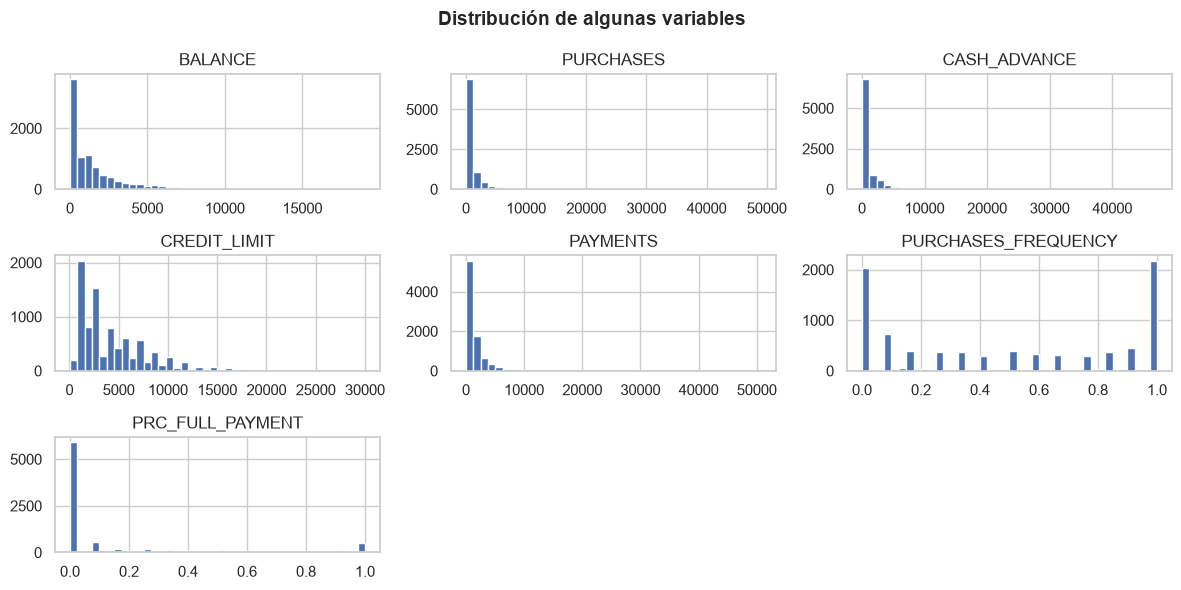

Sesgo (skew). Más de 1 = muy sesgada a la derecha:
BALANCE                2.4
PURCHASES              8.1
CASH_ADVANCE           5.2
CREDIT_LIMIT           1.5
PAYMENTS               5.9
PURCHASES_FREQUENCY    0.1
PRC_FULL_PAYMENT       1.9
dtype: float64


In [12]:
# Pintar histogramas de unas cuantas variables (df[cols].hist...) y observar el sesgo.
cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
df[cols].hist(bins=40, figsize=(12, 6), color="#4c72b0", edgecolor="white",  layout=(3, 3))
plt.suptitle("Distribución de algunas variables", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
# Medimos el sesgo (skew): ≈ 0 simétrica, > 1 muy sesgada a la derecha
print("Sesgo (skew). Más de 1 = muy sesgada a la derecha:")
print(df[cols].skew().round(1))

> **📝 Observación:**
> - Las variables de **dinero** están muy **sesgadas a la derecha** (skew > 1 en todas; `PURCHASES` llega a **8,1**):
>   casi todos los clientes se concentran a la izquierda y unos pocos tienen valores enormes
>   (`PURCHASES`, `CASH_ADVANCE` y `PAYMENTS` llegan a ~50.000). El **52 %** de los clientes **no usa nunca** el adelanto de efectivo.
> - `CREDIT_LIMIT` está menos sesgado (skew 1,5) y muestra picos en **cifras redondas** (1.000, 3.000…): los bancos asignan límites redondos.
> - `PURCHASES_FREQUENCY` tiene **forma de U** (skew ≈ 0,1: simétrica, no sesgada): el 23 % **nunca** compra con la tarjeta
>   y el 24 % compra **todos los meses**. Ya se intuyen **perfiles de cliente opuestos**.
> - `PRC_FULL_PAYMENT` (skew 1,9): el **66 %** de los clientes **nunca** paga la deuda completa y solo el 5,5 % la paga siempre
>   → la mayoría "arrastra" deuda (y paga intereses).
> - Consecuencia: estas diferencias de escala y los valores extremos refuerzan la necesidad de **escalar** antes del clustering.

### Escalado

K-Means, PCA y casi todos los algoritmos de distancia son **sensibles a la escala**. `CREDIT_LIMIT` llega a miles y `PURCHASES_FREQUENCY` está entre 0 y 1: sin escalar, las variables grandes dominarían. Estandarizamos (media 0, desviación 1).

**¿Qué hace `StandardScaler`?** Transforma cada columna así: **z = (x − media) / desviación típica**.
Después, todas las variables tienen **media 0 y desviación 1**: ninguna domina por tener números más grandes.

**Analogía:** un alumno saca un **8/10** en matemáticas y un **72/100** en historia. ¿En cuál le ha ido mejor?
Comparar 8 con 72 no tiene sentido; lo que sí tiene sentido es preguntar **cuánto está por encima de la media de la clase**.
Eso es justo lo que hace el escalado: expresa cada valor como "cuántas desviaciones está de la media".

- z = 0 → justo en la media · z = +2 → muy por encima · z = −1 → por debajo.
- Escalamos **todo `df`** (no hay train/test: es clustering, igual que con las setas).

In [11]:
# Aplicar StandardScaler a df -> X (array escalado)
scaler = StandardScaler()
X = scaler.fit_transform(df)          # cada columna → media 0, desviación 1

# Comprobación: medias ≈ 0 y desviaciones ≈ 1
pd.DataFrame(X, columns=df.columns).describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
BALANCE,0.0,1.0,-0.75,8.40
BALANCE_FREQUENCY,0.0,1.0,-3.70,0.52
PURCHASES,0.0,1.0,-0.47,22.48
ONEOFF_PURCHASES,0.0,1.0,-0.36,24.20
INSTALLMENTS_PURCHASES,0.0,1.0,-0.45,24.43
CASH_ADVANCE,0.0,1.0,-0.47,22.01
PURCHASES_FREQUENCY,-0.0,1.0,-1.22,1.27
ONEOFF_PURCHASES_FREQUENCY,-0.0,1.0,-0.68,2.67
PURCHASES_INSTALLMENTS_FREQUENCY,0.0,1.0,-0.92,1.60
CASH_ADVANCE_FREQUENCY,0.0,1.0,-0.68,6.82


> **📝 Observación:** Tras escalar, todas las variables tienen **media 0 y desviación 1** (el `-0.0` es solo redondeo de decimales).
> Pero el escalado **no elimina los valores extremos**: el máximo de `MINIMUM_PAYMENTS` está a **32 desviaciones** de la media,
> y varias variables de compras superan las 20. K-Means es sensible a estos valores, así que pueden aparecer **clusters pequeños de clientes extremos**.

## PCA

Con 17 variables no podemos pintar un scatter directo. Usamos PCA para (1) ver cuánta información retiene cada componente y (2) proyectar a 2D.

In [ ]:
# 1. Ajustar PCA sin fijar n_components y mirar explained_variance_ratio_
# 2. Pintar la varianza explicada acumulada (scree plot)
# 3. Decidir cuantas componentes hacen falta para ~80% de varianza

In [ ]:
# Proyectar X a 2 componentes y pintar el scatter (aun sin colores: no hay etiqueta)

A diferencia de las setas, aquí no vemos grupos separados a simple vista: es más bien una **nube continua**. El clustering nos ayudará a trazar fronteras útiles dentro de ella.

## Clustering: ¿cuántos segmentos? Codo + Silhouette

In [ ]:
k_values = range(2, 9)
inercias, silhouettes = [], []
for k in k_values:
    # Ajustar KMeans y guardar inercia + silhouette
    pass
# Pintar las dos curvas y elegir best_k (el de mayor silhouette)

### K-Means final

In [ ]:
# Entrenar KMeans con best_k, guardar las etiquetas y mirar el tamano de cada cluster

### Comparativa de algoritmos

Sin etiqueta, comparamos con **métricas internas**: *silhouette* y *Calinski-Harabasz* (más alto = mejor) y *Davies-Bouldin* (más bajo = mejor).

In [ ]:
# Definir evaluar(nombre, labels, X) con silhouette, davies_bouldin y calinski_harabasz
# (sin ARI: no hay etiqueta). Comparar KMeans, Aglomerativo y GMM.

### Dendrograma

In [ ]:
# linkage + dendrogram sobre una muestra de X

### DBSCAN: ¿hay clusters de densidad aquí?

Probamos DBSCAN. Veréis que en alta dimensión tiende a juntar casi todo en **un solo cluster** y marcar el resto como **ruido**. Eso nos dice algo importante: estos datos son una nube continua, no grupos separados por densidad. Aquí DBSCAN funciona mejor como **detector de atípicos** que como segmentador.

In [ ]:
# Ejecutar DBSCAN sobre la proyeccion PCA(2). Observar cuantos clusters y cuanto ruido.

### Visualización de los segmentos (t-SNE)

Proyectamos con t-SNE (sobre una muestra) y coloreamos por el segmento de K-Means.

In [ ]:
# t-SNE sobre una muestra de X, coloreado por el cluster de KMeans

## Interpretación de los segmentos

Lo más importante en segmentación: **¿qué caracteriza a cada grupo?** Calculamos la media de cada variable por cluster y la estandarizamos entre clusters (rojo = por encima de la media, azul = por debajo). Así leemos el «perfil» de cada segmento.

In [ ]:
# 1. Anadir la columna 'cluster' al df original (sin escalar)
# 2. Calcular la media de cada variable por cluster
# 3. Estandarizar entre clusters y pintar un heatmap (perfil de cada segmento)

Leyendo el heatmap se pueden nombrar los segmentos en términos de **negocio**, por ejemplo: clientes de alto saldo y muchas compras (VIP), clientes que tiran de adelantos de efectivo (riesgo), clientes poco activos, etc. Ese nombre y la estrategia asociada es justo el entregable que pide el caso.

## Detección de anomalías (Isolation Forest)

Identificamos los clientes con comportamiento más atípico (posible fraude, errores de datos o clientes premium fuera de norma).

In [ ]:
# IsolationForest sobre X, marcar los atipicos (-1) y pintarlos sobre PCA(2)

---
## Para ir más allá (opcional)

- **Ingeniería de KPIs**: derivar variables como *ratio de uso del límite* (`BALANCE / CREDIT_LIMIT`) o *compra media por transacción* suele mejorar mucho los segmentos.
- **UMAP / HDBSCAN** para visualización y clustering por densidad más robusto.
- **Transformación logarítmica** de las variables sesgadas antes de escalar.

## Conclusiones

- Sin etiqueta, la segmentación se valida con métricas internas (*silhouette*, etc.) y, sobre todo, con la **interpretabilidad** de los perfiles.
- Imputar y **escalar** fue imprescindible aquí (a diferencia de las setas).
- K-Means, GMM y Aglomerativo dan segmentos coherentes; DBSCAN reveló que los datos son una nube continua (mejor como detector de atípicos).
- El heatmap de perfiles convierte los clusters en **segmentos de negocio accionables**.